In [1]:
import torch
import os
import matplotlib.pyplot as plt
import numpy as np
from torchvision import datasets, transforms

from sklearn.metrics.pairwise import euclidean_distances

In [5]:
import sys
sys.path.append("/Users/nicolekan/Workspace/nus/data_valuation/src")

In [2]:
dir_data="/Users/nicolekan/Workspace/nus/data_valuation/data/"
dir_tensors = os.path.join("/Users/nicolekan/Workspace/nus/data_valuation/influences", "mnist")
dir_ckpt = "/Users/nicolekan/Workspace/nus/data_valuation/checkpoint/"

num_epochs = 10
ckpt_min = 3
ckpt_max = 10
ckpt_step = 3
p = 0.95
checkpoint_labels =  list(range(ckpt_min, ckpt_max, ckpt_step))

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x.view(-1)) 
])
    
mnist_train = datasets.MNIST(dir_data, train=True, download=False, transform=transform)

In [6]:
save_objs_dict = torch.load(f"{dir_tensors}/accuracies_and_losses.pt", weights_only=False)

train_losses = save_objs_dict["model_eval_obj"].train_losses
validation_losses = save_objs_dict["model_eval_obj"].validation_losses
accuracies = save_objs_dict["model_eval_obj"].accuracies

In [ ]:
# train_losses = torch.load(f"{dir_tensors}/mnist_train_losses.pt", weights_only=False)
# validation_losses = torch.load(f"{dir_tensors}/mnist_validation_losses.pt", weights_only=False)
# accuracies = torch.load(f"{dir_tensors}/mnist_accuracies.pt", weights_only=False)

In [5]:
epochs_range = range(1, num_epochs + 1)
train_losses = [loss.item() for loss in train_losses]

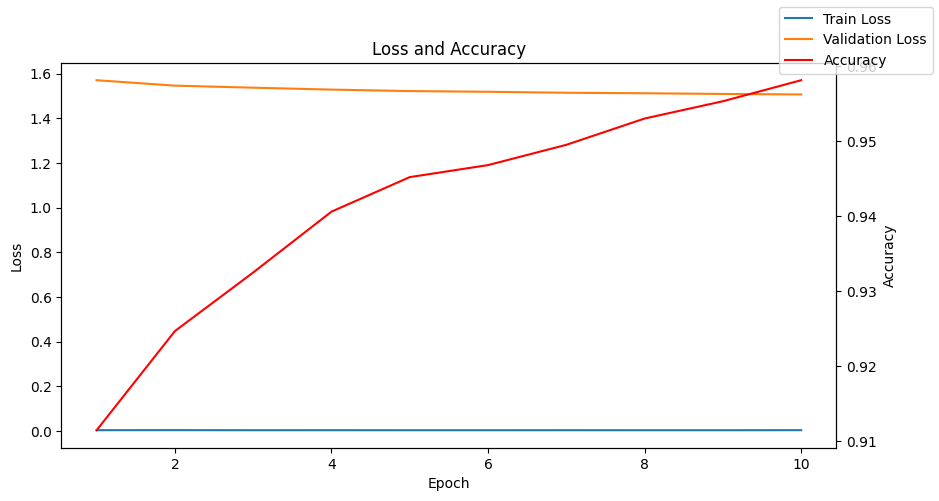

In [6]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(epochs_range, train_losses, label='Train Loss')
ax1.plot(epochs_range, validation_losses, label='Validation Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')

ax2 = ax1.twinx()
ax2.plot(epochs_range, accuracies, label='Accuracy', color='r')
ax2.set_ylabel('Accuracy')

plt.title('Loss and Accuracy')
fig.legend()
plt.show()

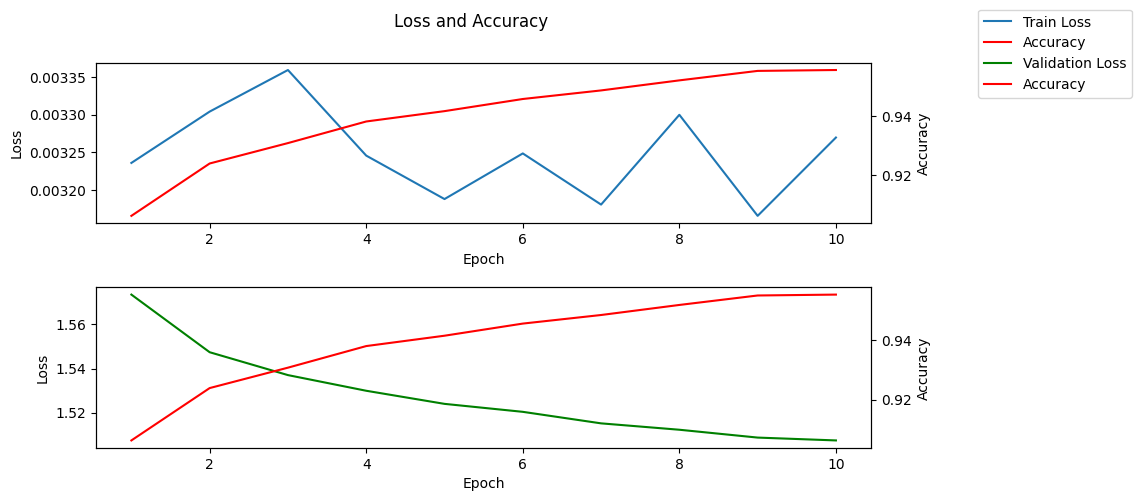

In [8]:
x_vals = np.arange(1, 11)
fig = plt.figure(figsize=(10, 5))
ax1 = fig.add_subplot(211)
ax1.plot(x_vals, train_losses, label='Train Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')

ax2 = ax1.twinx()
ax2.plot(x_vals, accuracies, label='Accuracy', color='r')
ax2.set_ylabel('Accuracy')

ax3 = fig.add_subplot(212)
ax3.plot(x_vals, validation_losses, label='Validation Loss', color='g')
ax4 = ax3.twinx()
ax3.set_xlabel('Epoch')
ax3.set_ylabel('Loss')
ax4.plot(x_vals, accuracies, label='Accuracy', color='r')
ax4.set_ylabel('Accuracy')

fig.suptitle('Loss and Accuracy')
fig.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.subplots_adjust(hspace=0.4)
plt.show()

# Influences

In [7]:
mnist_influences = save_objs_dict["mnist_influences"]

In [9]:
def top_or_least_influences(ckpt_influences, train_dataset, num_per_row=10, descending=True):
    ckpt_num = len(ckpt_influences)
    # fig, ax = plt.subplots(ckpt_num, num_per_row, figsize=(20, 20))
    ckpt_imgs = []
    for ckpt, influences in enumerate(ckpt_influences):
        sorted_influences = torch.argsort(torch.from_numpy(influences), descending=descending)
        top_indexes = sorted_influences[:num_per_row]
        top_influential_train_data = [train_dataset[index] for index in top_indexes]
        ckpt_imgs.append(top_influential_train_data)
    return ckpt_imgs
    
mnist_ckpt_imgs = top_or_least_influences(mnist_influences, mnist_train, num_per_row=20)
num_data = len(mnist_train)
x_vals =  list(range(1, 11))

In [9]:
validate_accuracies = save_objs_dict["val_model_eval_obj"].accuracies
validate_validation_losses = save_objs_dict["val_model_eval_obj"].validation_losses
rand_validate_accuracies = save_objs_dict["rand_model_eval_obj"].accuracies
rand_validate_train_losses = save_objs_dict["rand_model_eval_obj"].train_losses

In [16]:
checkpoints_filepaths = [os.path.join(dir_ckpt, f"epoch_{epoch}_{epoch/num_epochs}.pth") for epoch in checkpoint_labels]
checkpoints_filepaths

['/Users/nicolekan/Workspace/nus/data_valuation/checkpoint/epoch_3_0.3.pth',
 '/Users/nicolekan/Workspace/nus/data_valuation/checkpoint/epoch_6_0.6.pth',
 '/Users/nicolekan/Workspace/nus/data_valuation/checkpoint/epoch_9_0.9.pth']

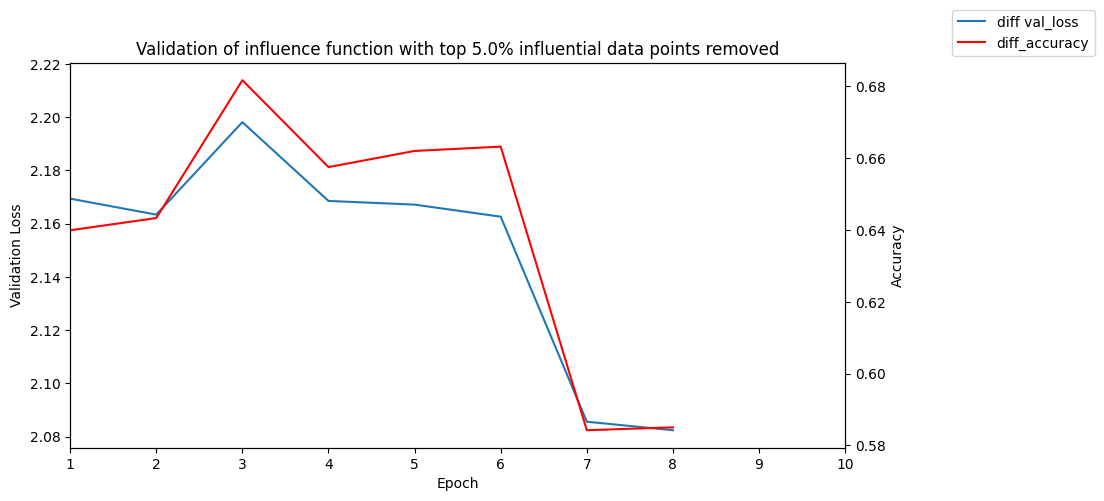

In [15]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
def concat_ckpt_metrics(metrics, ckpt_labels):
    integrate_metrics = []
    for i, metric in enumerate(metrics):
        prev_ckpt = ckpt_labels[i-1] if i > 0 else 0
        integrate_metrics.append(metric[prev_ckpt:])
    return np.concatenate(integrate_metrics)

diff_val_loss = concat_ckpt_metrics(validate_validation_losses, checkpoint_labels) - concat_ckpt_metrics(rand_validate_train_losses, checkpoint_labels) # suppose positive
diff_accuracy = concat_ckpt_metrics(rand_validate_accuracies, checkpoint_labels) - concat_ckpt_metrics(validate_accuracies, checkpoint_labels) # suppose positive

ax1.plot(diff_val_loss, label='diff val_loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Validation Loss')

ax2 = ax1.twinx()
ax2.plot(diff_accuracy, label='diff_accuracy', color='r')
ax2.set_ylabel('Accuracy')
plt.title(f'Validation of influence function with top {np.round(1-p, 2)*100}% influential data points removed')
fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

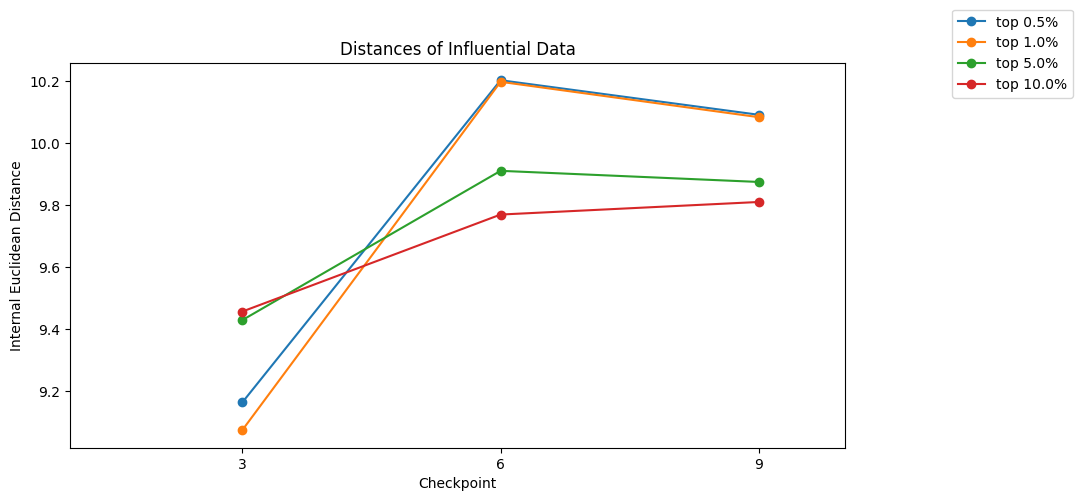

In [18]:
def calc_inter_dist(imgs):
    distances = euclidean_distances(imgs, imgs)
    mean_distance = np.mean(distances)
    return mean_distance

# Calculate distance of influential points towards other images
def calc_external_dist(inf_imgs, other_imgs):
    distances = euclidean_distances(inf_imgs, other_imgs)
    mean_distance = np.mean(distances)
    return mean_distance

# test selecting 0.5% 1% 5% 10% influential points
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
plt.title("Distances of Influential Data")
for p in [0.005, 0.01, 0.05, 0.1]:
    mnist_ckpt_imgs = top_or_least_influences(mnist_influences, mnist_train, num_per_row=int(p*num_data))
    inter_distances = []
    for ckpt, ckpt_imgs in enumerate(mnist_ckpt_imgs):
        ckpt_imgs = np.array([img[0] for img in ckpt_imgs])
        # print(f"checkpoint: {ckpt}, shape:{ckpt_imgs.shape}")
        mean_dist = calc_inter_dist(ckpt_imgs)
        inter_distances.append(mean_dist)
    ax1.plot(checkpoint_labels, inter_distances, 'o-', label=f"top {p*100}%")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Internal Euclidean Distance")
ax1.set_xticks(checkpoint_labels)
fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()